# `roselab_responsiveness`: sanity check of the production run

The schema went live on 2026-11-19. The worker on ibehaveGPU1 computes:

* **Curations:** the latest curation of every scan with moving gratings, natural images or the checkerboard.
* **Trace types:** CASCADE 25 ms and OASIS, and dF/F0 recipe 2 where it is stored.
* **Windows:** the standard read-outs.
* **Calibration:** one random-onset control per subject and paradigm.

This notebook checks whether the run did what it should. Every check ends in a row of the **verdict table** at the
bottom: what was expected, what was found, pass or look. Everything is read-only (server-side read-only session,
virtual modules), and all counts are aggregated on the server.

| Paradigm | Standard read-out | Responsiveness | Reliability (oracle) |
|---|---|---|---|
| gratings | 16 (stimulus on screen; baseline [on−60, on−10) frames) | t-test of read-out 16, or ZETA on its epoch | ≥ 0.18 |
| natural images | 11 (CASCADE), 3 (OASIS) | ZETA on that read-out's epoch | ≥ 0.08 |
| checkerboard | 1 | ZETA on read-out 1's epoch | — |

In [1]:
import os, logging, warnings
warnings.filterwarnings("ignore")
logging.getLogger("datajoint").setLevel(logging.WARNING)      # keeps the server address out of the outputs
import numpy as np, pandas as pd
import matplotlib as mpl, matplotlib.pyplot as plt
import datajoint as dj
dj.logger.setLevel(logging.WARNING)                                   # after the import: keeps the server address out of the outputs
from IPython.display import display, Markdown

for _c in ("../dj_local_conf.json", "dj_local_conf.json", os.path.expanduser("~/adamacs/dj_local_conf.json")):
    if os.path.exists(_c):
        dj.config.load(_c); break
dj.config["database.use_tls"] = False
dj.config["display.limit"] = 8
dj.conn().query("SET SESSION transaction_read_only = 1")                 # read-only, enforced by the server
assert dj.conn().query("SELECT @@transaction_read_only").fetchone()[0] == 1
vm = lambda db: dj.create_virtual_module(db, db, create_schema=False, create_tables=False)
r, imaging, session, event, scan = vm("roselab_responsiveness"), vm("roselab_imaging"), vm("roselab_session"), vm("roselab_event"), vm("roselab_scan")
mpl.rcParams.update({"figure.dpi": 100, "font.size": 9, "axes.titlesize": 10, "axes.titleweight": "bold",
                     "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False})
COL = {"cascade25": "#e76f51", "oasis": "#2a9d8f", "dff0_r2": "#2b2d42"}
PAR = {"gratings": "gratings", "nat_images_repeated": "images", "rf_checkerboard": "checkerboard"}
STD_RO = {("gratings", "cascade25"): 16, ("gratings", "oasis"): 16, ("gratings", "dff0_r2"): 16,
          ("nat_images_repeated", "cascade25"): 11, ("nat_images_repeated", "oasis"): 3, ("nat_images_repeated", "dff0_r2"): 1,
          ("rf_checkerboard", "cascade25"): 1, ("rf_checkerboard", "oasis"): 1, ("rf_checkerboard", "dff0_r2"): 1}
SOMA = imaging.MaskClassification.MaskType & 'mask_type="soma"'
REJ = imaging.RoiQC.Rejected.proj()
subj = dict(zip(*session.Session.fetch("session_id", "subject")))
VERDICT = []
def verdict(check, expected, found, ok):
    VERDICT.append(dict(check=check, expected=expected, found=found, result="pass" if ok else "LOOK"))
base = lambda s: s.replace("_random", "")
print("connected read-only; tasks:", len(r.ResponseTask()))

connected read-only; tasks: 1786


## 1. Completion

For each table: the rows the staged tasks ask for, the rows computed, and the job table (reserved = running now,
error = failed). A table still in progress is not a failure; errors are.

In [2]:
T = r.ResponseTask
expect = {
    "EventSet": len(dj.U("session_id", "scan_id", "event_selector") & T),
    "ScanQuality": len(dj.U("session_id", "scan_id") & T),
    "Quality": len(dj.U("session_id", "scan_id", "paramset_idx", "curation_id") & T),
    "TraceQuality": len(dj.U("session_id", "scan_id", "paramset_idx", "curation_id", "trace_source") & T),
    "Readout": len(T.Readout()), "Zeta": len(T.Zeta()), "DirectionTuning": len(T.Tuning()),
}
expect["ScreenTiming"] = len(dj.U("session_id", "scan_id", "event_selector") & T & (r.EventSelector & "random_seed IS NULL"))
jobs = r.schema.jobs.proj("status", "error_message").fetch(format="frame").reset_index()
tn = {"EventSet": "__event_set", "ScreenTiming": "_screen_timing", "ScanQuality": "__scan_quality", "Quality": "__quality",
      "TraceQuality": "__trace_quality", "Readout": "__readout", "Zeta": "__zeta", "DirectionTuning": "__direction_tuning"}
rows = []
for t, n in expect.items():
    done = len(getattr(r, t)())
    js = jobs[jobs.table_name == tn[t]] if len(jobs) else jobs
    rows.append(dict(table=t, expected=n, computed=done, percent=round(100 * done / max(n, 1), 1),
                     running=int((js.status == "reserved").sum()) if len(js) else 0, errors=int((js.status == "error").sum()) if len(js) else 0))
COMP = pd.DataFrame(rows); display(COMP)
errs = jobs[jobs.status == "error"] if len(jobs) else jobs
if len(errs):
    display(errs.assign(error=errs.error_message.str[:160])[["table_name", "error"]].value_counts().reset_index().head(15))
verdict("all staged work computed", "100 % per table", f"{COMP.computed.sum()} / {COMP.expected.sum()} rows",
        bool((COMP.computed >= COMP.expected).all()))
verdict("no job errors", "0", str(int(COMP.errors.sum())), COMP.errors.sum() == 0)

,table,expected,computed,percent,running,errors
0,EventSet,618,618,100.0,0,0
1,ScanQuality,561,561,100.0,0,0
2,Quality,561,561,100.0,0,0
3,TraceQuality,1683,1683,100.0,0,0
4,Readout,5935,5935,100.0,0,0
5,Zeta,1225,1225,100.0,0,0
6,DirectionTuning,777,777,100.0,0,0
7,ScreenTiming,561,561,100.0,0,0


## 2. Inputs

* **Onsets (`EventSet`):** gratings 180 onsets × 12 directions; images 1,000 onsets × 100 images; checkerboard
  ≈ 700 onsets. No set may be empty.
* **Screen timing (`ScreenTiming`):** on rigs with a photodiode, the latency should be about 80–120 ms and most
  onsets detected.
* **Detector gain (`ScanQuality`):** positive or NULL, never negative; dark-referenced where shutter frames exist.
* **ROI QC:** ROIs without fluorescence are left out of every result below.

,sets,empty,onsets_median,onsets_min,conditions_median,ioi_median_s
event_selector,,,,,,
gratings,259,0,180.0,26,12.0,7.016
gratings_random,21,0,180.0,26,1.0,7.016
nat_images_repeated,269,0,1000.0,600,100.0,3.467
nat_images_repeated_random,19,0,1000.0,801,1.0,3.516
rf_checkerboard,33,0,700.0,348,69.0,3.000
rf_checkerboard_random,17,0,696.0,348,1.0,3.000


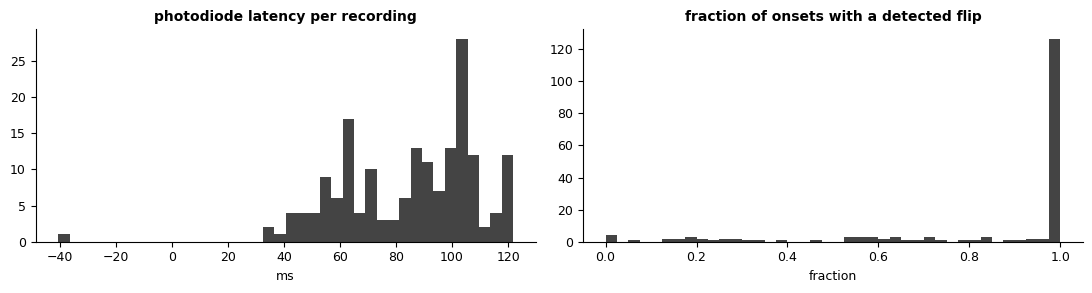

recordings with a diode: 180 of 561; latency median 90 ms (5–95 %: 46–119); detected median 1.00
ScanQuality: 561 scans; method {'dark': 506, 'ptc': 55}; gain NULL 47, negative 0; gain median 1463 grey levels/photon (5–95 %: 131–1754)


**20 scans with gain < 100 grey levels/photon** (expected ~1,000–1,800):

,session_id,scan_id,gain_method,gain,gain_r2,n_dark_frames,subject
28,sess9FNL55LW,scan9FNL55LW,dark,10.403895,0.110737,22,ROS-1794
35,sess9FNPVGBU,scan9FNPVGBU,dark,0.137008,-0.432808,20,ROS-1794
60,sess9FOYQS5Q,scan9FOYQS5Q,dark,46.479553,0.086638,21,ROS-1846
75,sess9FP13NJE,scan9FP13NJE,dark,86.444288,0.514495,21,ROS-1846
83,sess9FP29C72,scan9FP29C72,dark,97.813189,0.607540,22,ROS-1846
95,sess9FP41RZE,scan9FP41RZE,dark,42.008270,0.601029,21,ROS-1846
103,sess9FP58GM8,scan9FP58GM8,dark,10.360464,0.267644,21,ROS-1846
104,sess9FP59QVR,scan9FP59QVR,dark,13.753577,0.316436,21,ROS-1846
121,sess9FP85U47,scan9FP85U47,dark,23.595782,0.432137,25,ROS-1841
237,sess9FS20OGP,scan9FS20OGP,dark,20.568455,0.610767,20,ROS-1987


RoiQC on the 561 staged curations: checked 561; ROIs rejected 5356 of 719373 (0.7 %); curations with > half rejected: 0


In [3]:
E = r.EventSet.proj("n_onsets", "n_conditions", "median_ioi_s").fetch(format="frame").reset_index()
display(E.groupby("event_selector").agg(sets=("scan_id", "size"), empty=("n_onsets", lambda x: int((x == 0).sum())),
        onsets_median=("n_onsets", "median"), onsets_min=("n_onsets", "min"), conditions_median=("n_conditions", "median"),
        ioi_median_s=("median_ioi_s", "median")).round(3))
verdict("no empty onset sets", "0", str(int((E.n_onsets == 0).sum())), (E.n_onsets == 0).sum() == 0)
ST = r.ScreenTiming.proj("has_diode", "n_detected", "latency_s", "latency_iqr_s").fetch(format="frame").reset_index()
if len(ST):
    D_ = ST[ST.has_diode.astype(bool)].merge(E[["session_id", "scan_id", "event_selector", "n_onsets"]])
    D_["detected"] = D_.n_detected / D_.n_onsets.clip(lower=1)
    fig, ax = plt.subplots(1, 2, figsize=(11, 3))
    ax[0].hist(D_.latency_s.dropna() * 1e3, bins=40, color="#444"); ax[0].set(title="photodiode latency per recording", xlabel="ms")
    ax[1].hist(D_.detected, bins=40, color="#444"); ax[1].set(title="fraction of onsets with a detected flip", xlabel="fraction")
    plt.tight_layout(); plt.show()
    lat = D_.latency_s.dropna() * 1e3
    print(f"recordings with a diode: {len(D_)} of {len(ST)}; latency median {lat.median():.0f} ms (5–95 %: {lat.quantile(.05):.0f}–{lat.quantile(.95):.0f}); "
          f"detected median {D_.detected.median():.2f}")
    verdict("photodiode latency plausible", "median 70–130 ms", f"{lat.median():.0f} ms", 70 <= lat.median() <= 130 if len(lat) else False)
SQ = r.ScanQuality.proj("gain_method", "gain", "gain_r2", "n_dark_frames").fetch(format="frame").reset_index()
if len(SQ):
    g = SQ.gain.astype(float)
    print(f"ScanQuality: {len(SQ)} scans; method {SQ.gain_method.value_counts().to_dict()}; gain NULL {g.isna().sum()}, negative {(g < 0).sum()}; "
          f"gain median {g.median():.0f} grey levels/photon (5–95 %: {g.quantile(.05):.0f}–{g.quantile(.95):.0f})")
    verdict("no negative detector gain", "0", str(int((g < 0).sum())), (g < 0).sum() == 0)
    low = SQ[g < 100].assign(subject=lambda d: d.session_id.map(subj))
    if len(low):
        display(Markdown(f"**{len(low)} scans with gain < 100 grey levels/photon** (expected ~1,000–1,800):")); display(low.head(10))
TC = dj.U("session_id", "scan_id", "paramset_idx", "curation_id") & T
q = imaging.RoiQC & TC & {"roi_qc_criterion": "empty_f"}
n_rois, n_rej = q.fetch("n_rois", "n_rejected")
print(f"RoiQC on the {len(TC)} staged curations: checked {len(q)}; ROIs rejected {int(n_rej.sum())} of {int(n_rois.sum())} "
      f"({100 * n_rej.sum() / max(n_rois.sum(), 1):.1f} %); curations with > half rejected: {int((n_rej > n_rois / 2).sum())}")
verdict("RoiQC covers every staged curation", f"{len(TC)}", f"{len(q)}", len(q) == len(TC))

## 3. Calibration: random onsets

On the `*_random` sets every onset sits at a random time, so nothing is time-locked. At p < 0.05 about 5 % of soma
cells should come out "responsive". The pilot found 3.5–4.1 % for read-out 16 and for ZETA on its epoch (CASCADE,
OASIS), 6–8 % for ZETA on the short image epochs, and 9.4 % for read-out 16 on dF/F0 (which is why dF/F0 is never used
for calls).

In [4]:
def frac(rel, attr, by, extra=None):
    q = rel * SOMA - REJ if extra is None else (rel * SOMA - REJ) & extra
    a = dj.U(*by).aggr(q, n="count(*)", k=f"sum({attr} < 0.05)").fetch(format="frame").reset_index()
    a["pct"] = 100 * a.k / a.n.clip(lower=1); return a
by = ["event_selector", "trace_source", "readout_idx"]
RO_real = frac(r.Readout.Cell & "resp_p IS NOT NULL", "resp_p", by)
ZE_real = frac(r.Zeta.Cell, "zeta_p", by + ["zeta_idx"])
for df in (RO_real, ZE_real):
    df["paradigm"] = df.event_selector.map(base); df["random"] = df.event_selector.str.endswith("_random")
rs = set(E[E.event_selector.str.endswith("_random")].scan_id)          # compare on recordings that have a control
RO_c = frac(r.Readout.Cell & "resp_p IS NOT NULL" & [{"scan_id": s} for s in rs], "resp_p", by) if rs else RO_real.iloc[:0]
ZE_c = frac(r.Zeta.Cell & [{"scan_id": s} for s in rs], "zeta_p", by + ["zeta_idx"]) if rs else ZE_real.iloc[:0]
cal = []
for name, df, keys in (("read-out t-test", RO_c, by), ("ZETA", ZE_c, by + ["zeta_idx"])):
    if not len(df): continue
    df = df.assign(paradigm=df.event_selector.map(base), random=df.event_selector.str.endswith("_random"))
    p = df.pivot_table(index=["paradigm", "trace_source", "readout_idx"] + (["zeta_idx"] if "zeta_idx" in df else []),
                       columns="random", values="pct").rename(columns={False: "real %", True: "random %"})
    p["test"] = name; cal.append(p.reset_index())
CAL = pd.concat(cal) if cal else pd.DataFrame()
if len(CAL):
    display(CAL.round(1))
    calls = CAL[(CAL.trace_source != "dff0_r2")]
    worst = calls["random %"].max()
    verdict("false positives on random onsets (CASCADE, OASIS)", "≤ 8 % for every test", f"max {worst:.1f} %", worst <= 8)
    dff = CAL[(CAL.trace_source == "dff0_r2")]
    if len(dff): print(f"dF/F0 (not used for calls): random-onset rate {dff['random %'].min():.1f}–{dff['random %'].max():.1f} %")

random,paradigm,trace_source,readout_idx,real %,random %,test,zeta_idx
0,gratings,cascade25,2,63.516956,3.969466,read-out t-test,NaN
1,gratings,cascade25,15,65.849387,6.041439,read-out t-test,NaN
2,gratings,cascade25,16,72.973188,5.801527,read-out t-test,NaN
3,gratings,dff0_r2,2,63.574803,NaN,read-out t-test,NaN
4,gratings,dff0_r2,15,75.937008,NaN,read-out t-test,NaN
5,gratings,dff0_r2,16,75.755906,NaN,read-out t-test,NaN
6,gratings,oasis,2,63.165354,4.23622,read-out t-test,NaN
7,gratings,oasis,15,71.275591,6.070866,read-out t-test,NaN
8,gratings,oasis,16,75.661417,5.007874,read-out t-test,NaN
9,nat_images_repeated,cascade25,1,60.829386,4.48731,read-out t-test,NaN


dF/F0 (not used for calls): random-onset rate nan–nan %


## 4. Real onsets: responsive, reliable, activated

Per recording, the fraction of soma cells (ROI QC applied) that are responsive on the standard read-out of each
paradigm and trace, the fraction above the oracle threshold, and the fraction activated (response above baseline, or
above the trace mean for read-outs without a baseline).

recordings soma_cells responsive_t %  \
selector            trace_source                                         
gratings            cascade25            259     125672           71.9   
                    dff0_r2              259     125672          75.96   
                    oasis                259     125672          76.49   
nat_images_repeated cascade25            269     144125            NaN   
                    dff0_r2              269     144125          37.93   
                    oasis                269     144125            NaN   
rf_checkerboard     cascade25             33      18116          56.44   
                    dff0_r2               33      18116           74.4   
                    oasis                 33      18116          62.38   

                                 responsive_zeta % reliable % activated %  
selector            trace_source                                           
gratings            cascade25                81.34      56.22       60.28  
                    dff0_r2                    NaN      58.75       58.57  
                    oasis                    84.78      66.09       57.84  
nat_images_repeated cascade25                73.61      79.42        70.8  
                    dff0_r2                    NaN      66.57       61.97  
                    oasis                    74.62      82.06       74.43  
rf_checkerboard     cascade25                80.94      35.93       60.11  
                    dff0_r2                    NaN      54.43       73.99  
                    oasis                    77.53      38.13       63.96

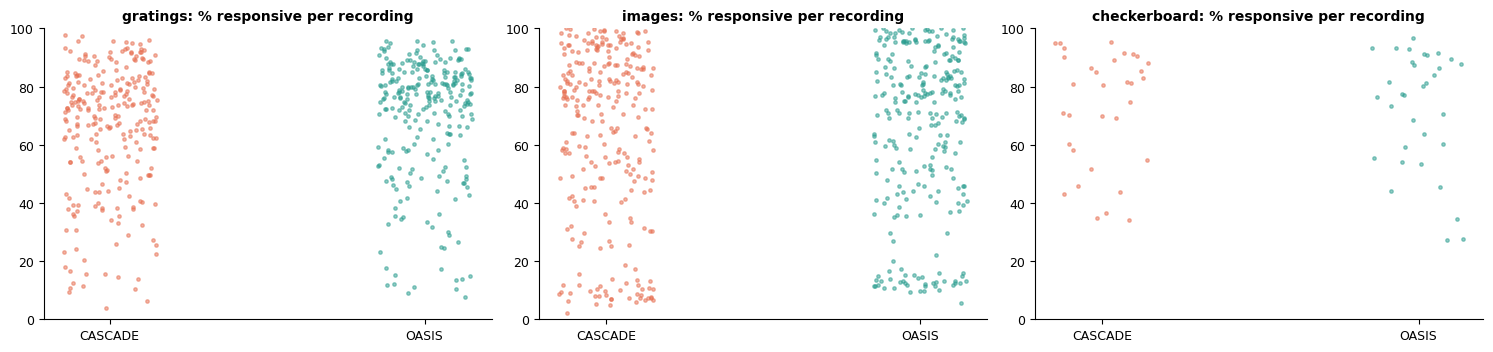

In [5]:
recs = []
for (sel, src), ro in STD_RO.items():
    q = (r.Readout.Cell * SOMA - REJ) & {"event_selector": sel, "trace_source": src, "readout_idx": ro}
    thr = 0.18 if sel == "gratings" else 0.08
    a = dj.U("session_id", "scan_id", "paramset_idx", "curation_id").aggr(
        q, n="count(*)", resp=f"avg(resp_p < 0.05)", rel=f"avg(oracle_r >= {thr})",
        pos="avg(COALESCE(resp_delta, resp_vs_trace) > 0)").fetch(format="frame").reset_index()
    if not len(a): continue
    zi = (r.Zeta.Cell * SOMA - REJ) & {"event_selector": sel, "trace_source": src, "readout_idx": ro, "zeta_idx": 1}
    z = dj.U("session_id", "scan_id", "paramset_idx", "curation_id").aggr(zi, zeta="avg(zeta_p < 0.05)").fetch(format="frame").reset_index()
    a = a.merge(z, how="left"); a["selector"] = sel; a["trace_source"] = src; a["readout"] = ro
    recs.append(a)
R = pd.concat(recs) if recs else pd.DataFrame()
if len(R):
    R["subject"] = R.session_id.map(subj)
    S_ = R.groupby(["selector", "trace_source"]).agg(recordings=("scan_id", "size"), soma_cells=("n", "sum"),
          responsive_t=("resp", "median"), responsive_zeta=("zeta", "median"), reliable=("rel", "median"), activated=("pos", "median"))
    display((S_ * [1, 1, 100, 100, 100, 100]).round(1).rename(columns=lambda c: c + (" %" if c not in ("recordings", "soma_cells") else "")))
    fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
    for a_, sel in zip(ax, ("gratings", "nat_images_repeated", "rf_checkerboard")):
        d = R[(R.selector == sel) & (R.trace_source != "dff0_r2")]
        for j, src in enumerate(("cascade25", "oasis")):
            v = d[d.trace_source == src]["zeta" if sel != "gratings" else "resp"].dropna() * 100
            a_.scatter(np.full(len(v), j) + np.random.uniform(-.15, .15, len(v)), v, s=6, alpha=.5, color=COL[src])
        a_.set_xticks([0, 1]); a_.set_xticklabels(["CASCADE", "OASIS"]); a_.set(title=f"{PAR[sel]}: % responsive per recording", ylim=(0, 100))
    plt.tight_layout(); plt.show()
    g16 = R[(R.selector == "gratings") & (R.trace_source == "cascade25")]
    if len(g16):
        verdict("gratings responsive (CASCADE, read-out 16)", "median 50–95 % (pilot 79 %)", f"{100 * g16.resp.median():.0f} %", 50 <= 100 * g16.resp.median() <= 95)
        verdict("gratings activated among all soma (CASCADE)", "majority > 50 %", f"{100 * g16.pos.median():.0f} %", g16.pos.median() > .5)
    im_ = R[(R.selector == "nat_images_repeated") & (R.trace_source == "oasis")]
    if len(im_):
        verdict("images responsive (OASIS, ZETA on read-out 3)", "median 40–95 % (pilot 79 %)", f"{100 * im_.zeta.median():.0f} %", 40 <= 100 * im_.zeta.median() <= 95)
    zero = R[(R.trace_source != "dff0_r2") & (R.selector != "rf_checkerboard") & (R.resp.fillna(R.zeta) < 0.02)]
    if len(zero):
        display(Markdown(f"**{len(zero)} recordings with < 2 % responsive cells** (check the stimulus or the curation):"))
        display(zero[["subject", "scan_id", "paramset_idx", "curation_id", "selector", "trace_source", "n", "resp", "zeta"]].head(15))

## 5. Grating tuning (read-out 16, Mazurek et al. 2014, tuning setting 1)

Expected:

* orientation selectivity (1 − CirVar) mostly below 0.5, with a tail of sharply tuned cells;
* preferred directions spread over all 12 directions, without a single dominant one;
* a substantial fraction of cells with Hotelling p < 0.05.

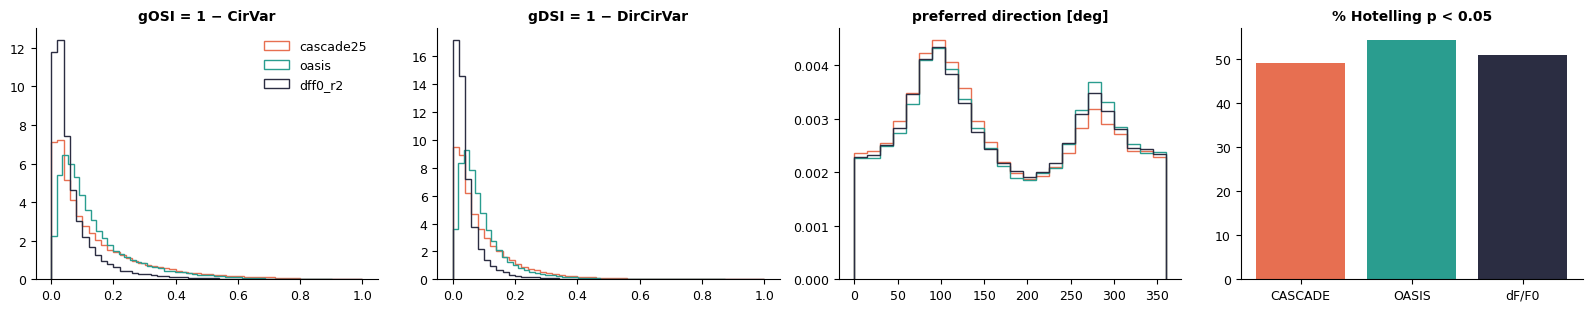

In [6]:
DT = ((r.DirectionTuning.Cell * SOMA - REJ) & {"readout_idx": 16, "tuning_idx": 1}).proj(
    "gosi", "gdsi", "hotelling_p", "pref_dir", "osi", "dsi").fetch(format="frame").reset_index()
if len(DT):
    fig, ax = plt.subplots(1, 4, figsize=(16, 3.2))
    for src in ("cascade25", "oasis", "dff0_r2"):
        d = DT[DT.trace_source == src]
        ax[0].hist(d.gosi.dropna(), bins=50, histtype="step", color=COL[src], label=src, density=True)
        ax[1].hist(d.gdsi.dropna(), bins=50, histtype="step", color=COL[src], density=True)
        ax[2].hist(d.pref_dir.dropna(), bins=np.arange(0, 361, 15), histtype="step", color=COL[src], density=True)
    ax[0].set(title="gOSI = 1 − CirVar"); ax[0].legend(); ax[1].set(title="gDSI = 1 − DirCirVar"); ax[2].set(title="preferred direction [deg]")
    ax[3].bar(range(3), [100 * np.mean(DT[DT.trace_source == s].hotelling_p.astype(float) < .05) for s in ("cascade25", "oasis", "dff0_r2")],
              color=[COL[s] for s in ("cascade25", "oasis", "dff0_r2")]); ax[3].set_xticks(range(3)); ax[3].set_xticklabels(["CASCADE", "OASIS", "dF/F0"])
    ax[3].set(title="% Hotelling p < 0.05")
    plt.tight_layout(); plt.show()
    c = DT[DT.trace_source == "cascade25"]
    h, _ = np.histogram(c.pref_dir.dropna(), bins=np.arange(0, 361, 30))
    verdict("preferred directions spread (CASCADE)", "no 30° bin > 25 % of cells", f"max bin {100 * h.max() / max(h.sum(), 1):.0f} %", h.max() / max(h.sum(), 1) < .25)
    verdict("orientation-tuned cells (CASCADE, Hotelling p < 0.05)", "10–80 %", f"{100 * np.mean(c.hotelling_p.astype(float) < .05):.0f} %",
            10 <= 100 * np.mean(c.hotelling_p.astype(float) < .05) <= 80)

## 6. Integrity of the stored windows and values

* **Window edges:** every read-out stores the window it used, relative to the DataJoint onset. For a given read-out
  and paradigm these edges must be the same across recordings (up to the display latency and one frame).
* **ZETA epochs:** they must match their read-out's edges.
* **Values:** CASCADE values stay in range (the audit's cut is 50), and the trial values are finite for the onsets
  inside the recording.

In [7]:
RW = r.Readout.proj("n_onsets", "latency_s", "latency_source", "resp_start_s", "resp_stop_s", "base_start_s", "base_stop_s").fetch(format="frame").reset_index()
if len(RW):
    RW["paradigm"] = RW.event_selector.map(base)
    W = RW.groupby(["paradigm", "readout_idx"]).agg(n=("scan_id", "size"), resp_start=("resp_start_s", "median"), resp_start_sd=("resp_start_s", "std"),
         resp_stop=("resp_stop_s", "median"), resp_stop_sd=("resp_stop_s", "std"), base_start=("base_start_s", "median"), base_stop=("base_stop_s", "median"),
         latency=("latency_s", "median"), diode=("latency_source", lambda s: int((s == "photodiode").sum())))
    display(W.round(3))
    # start edges are anchored to the onset and must agree; stop edges anchored to the offset follow each protocol's
    # stimulus duration (e.g. gratings 0.6 s sweeps in 2023, 3 s in 2024+), so their spread is not checked
    spread = W.resp_start_sd.max()
    verdict("window start edges consistent across recordings", "SD ≤ 0.08 s (latency + 1 frame)", f"max SD {spread:.3f} s", spread <= .08)
    ev = RW.merge(E[["session_id", "scan_id", "event_selector", "n_onsets"]].rename(columns={"n_onsets": "set_onsets"}))
    lost = (1 - ev.n_onsets / ev.set_onsets.clip(lower=1))
    verdict("onsets used by the read-outs", "≥ 95 % of each set", f"min {100 * (1 - lost.max()):.0f} %", lost.max() <= .05)
ZW = (r.Zeta.proj("epoch_start_s", "window_s") * r.Readout.proj("resp_start_s", "resp_stop_s", "base_start_s")).fetch(format="frame").reset_index()
if len(ZW):
    zs = ZW.base_start_s.where(ZW.base_start_s.notna() & (ZW.zeta_idx != 3), ZW.resp_start_s)
    dev = (ZW.epoch_start_s - zs).abs().max(); dev2 = (ZW.epoch_start_s + ZW.window_s - ZW.resp_stop_s).abs().max()
    verdict("ZETA epochs equal their read-out's edges", "≤ 0.07 s", f"start {dev:.3f} s, end {dev2:.3f} s", max(dev, dev2) <= .07)
TQ = (r.TraceQuality.Cell * SOMA - REJ).proj("max_value").fetch(format="frame").reset_index() if len(r.TraceQuality()) else pd.DataFrame()
if len(TQ):
    for src, d in TQ.groupby("trace_source"):
        mv = d.max_value.astype(float)
        print(f"{src}: max trace value median {mv.median():.2f}, 99th pct {mv.quantile(.99):.2f}, > 50: {int((mv > 50).sum())} of {len(mv)}")
    c = TQ[TQ.trace_source == "cascade25"].max_value.astype(float)
    if len(c): verdict("CASCADE values in range", "≤ 1 % of soma above 50", f"{100 * np.mean(c > 50):.2f} %", np.mean(c > 50) <= .01)
sample = (r.Readout & {"readout_idx": 16, "event_selector": "gratings"}).fetch("KEY", limit=5)
if sample:
    tr = np.concatenate([np.vstack((r.Readout.Cell & k).fetch("trial_resp", limit=50)) for k in sample])
    print(f"trial_resp sample ({tr.shape[0]} cells): finite {100 * np.isfinite(tr).mean():.1f} %")

n  resp_start  resp_start_sd  resp_stop  \
paradigm            readout_idx                                              
gratings            2            813       0.000          0.001      2.905   
                    15           813       0.100          0.016      3.112   
                    16           813       0.100          0.016      3.112   
nat_images_repeated 1            841       0.100          0.014      0.602   
                    3            841       0.100          0.009      0.668   
                    11           841      -0.033          0.003      0.501   
                    14           841       0.100          0.009      0.602   
rf_checkerboard     1            132       0.100          0.016      1.100   

                                 resp_stop_sd  base_start  base_stop  latency  \
paradigm            readout_idx                                                 
gratings            2                   0.228      -2.938     -0.033      0.0   
                    15                  0.231      -0.968      0.033      0.1   
                    16                  0.231      -1.903     -0.234      0.1   
nat_images_repeated 1                   0.018      -0.400      0.100      0.1   
                    3                   0.035         NaN        NaN      0.0   
                    11                  0.045         NaN        NaN      0.0   
                    14                  0.014       0.000      0.100      0.0   
rf_checkerboard     1                   0.166      -0.400      0.100      0.1   

                                 diode  
paradigm            readout_idx         
gratings            2                0  
                    15             207  
                    16             207  
nat_images_repeated 1              279  
                    3                0  
                    11               0  
                    14               0  
rf_checkerboard     1               42

cascade25: max trace value median 1.25, 99th pct 7.69, > 50: 1883 of 287913
dff0_r2: max trace value median 3.09, 99th pct 67.60, > 50: 3292 of 287913
oasis: max trace value median 1313.46, 99th pct 8015.39, > 50: 287796 of 287913
trial_resp sample (250 cells): finite 100.0 %


## 6b. The measures added on 2026-11-20 (design doc section 2.5)

Calibrated the same way as section 3, on the recordings that have a random-onset control:

* **Group tests:**
  * `resp_anova_p` (all response vs all baseline values) should call about 5 % of soma cells on random onsets. The
    pilot gave 2–7 %.
  * `resp_kw_p` should call about 8 %. It is stored only for read-outs whose response and baseline windows are
    equally long.
  * The Holm-corrected per-condition tests (`cond_resp_*`) should stay near 5 %.
* **Effect size:** `resp_auroc` should be about 0.5 on random onsets. It is stored only for equally long windows.
* **Reliability:** on random onsets, `signal_var` should be ≤ 0 for about half the cells, and `fev` > 0.15 (Cadena's
  cut) should be rare.
* **Ranges:** AUROC and sparseness lie in [0, 1], FEV ≤ 1, and `cc_max` lies in [0, 1].
* **Tuning:** the cross-validated `gosi_cv` should be near 0 on random onsets, and should rise with `gosi` on
  real gratings.

In [8]:
by = ["event_selector", "trace_source", "readout_idx"]
NEWQ = dict(n="count(*)", anova="avg(resp_anova_p < 0.05)", n_kw="sum(resp_kw_p IS NOT NULL)",
            kw="sum(resp_kw_p < 0.05) / nullif(sum(resp_kw_p IS NOT NULL), 0)",
            c_anova="avg(cond_resp_anova_p < 0.05)", c_kw="sum(cond_resp_kw_p < 0.05) / nullif(sum(cond_resp_kw_p IS NOT NULL), 0)",
            auroc="avg(resp_auroc)", n_auroc="sum(resp_auroc IS NOT NULL)", fev15="avg(fev > 0.15)", n_fev="sum(fev IS NOT NULL)",
            sv_le0="avg(signal_var <= 0)", n_sparse="sum(lifetime_sparseness IS NOT NULL)",
            bad_range="sum(resp_auroc < 0 OR resp_auroc > 1 OR fev > 1.000001 OR cc_max < 0 OR cc_max > 1.000001 "
                      "OR lifetime_sparseness < -1e-6 OR lifetime_sparseness > 1.000001)")
cells = (r.Readout.Cell * SOMA - REJ) & [{"scan_id": s} for s in rs] if rs else None
NM = dj.U(*by).aggr(cells, **NEWQ).fetch(format="frame").reset_index() if cells is not None else pd.DataFrame()
if len(NM):
    for c in NM.columns[3:]: NM[c] = pd.to_numeric(NM[c], errors="coerce")
    NM["paradigm"] = NM.event_selector.map(base); NM["random"] = NM.event_selector.str.endswith("_random")
    # window lengths per read-out and paradigm: KW / AUROC must be stored exactly where the windows are equally long
    WL = RW.assign(dl=(RW.resp_stop_s - RW.resp_start_s) - (RW.base_stop_s - RW.base_start_s)).groupby(
        ["paradigm", "readout_idx"]).dl.apply(lambda s: s.abs().max()).rename("len_diff_s").reset_index()
    NM = NM.merge(WL, how="left")
    NM["equal_windows"] = NM.len_diff_s <= 1.5 / 30
    show = NM.pivot_table(index=["paradigm", "trace_source", "readout_idx", "equal_windows"], columns="random",
                          values=["anova", "kw", "c_anova", "c_kw", "auroc", "fev15", "sv_le0"])
    show.columns = [f"{v} {'random' if rnd else 'real'}" for v, rnd in show.columns]
    pct = [c for c in show.columns if not c.startswith("auroc")]
    show[pct] = show[pct] * 100
    display(show.round(2))
    rnd = NM[NM.random & (NM.trace_source != "dff0_r2")]
    verdict("resp_anova_p on random onsets (CASCADE, OASIS)", "≤ 8 % for every read-out", f"max {100 * rnd.anova.max():.1f} %", rnd.anova.max() <= .08)
    kwr = rnd.dropna(subset=["kw"])
    if len(kwr): verdict("resp_kw_p on random onsets (equal windows)", "≤ 10 %", f"max {100 * kwr.kw.max():.1f} %", kwr.kw.max() <= .10)
    holm = rnd.dropna(subset=["c_anova"])
    if len(holm): verdict("Holm per-condition ANOVA on random onsets", "≤ 8 %", f"max {100 * holm.c_anova.max():.1f} %", holm.c_anova.max() <= .08)
    au = rnd.dropna(subset=["auroc"])
    if len(au): verdict("AUROC on random onsets", "0.47–0.53", f"{au.auroc.min():.3f}–{au.auroc.max():.3f}", au.auroc.between(.47, .53).all())
    # per recording: KW / AUROC must be stored exactly where that recording's windows are equally long (± 1.5 frames)
    PK = r.Readout.primary_key
    per = dj.U(*PK).aggr(r.Readout.Cell, n_kw="sum(resp_kw_p IS NOT NULL)", n_au="sum(resp_auroc IS NOT NULL)").fetch(format="frame").reset_index()
    fr = dict(zip(*(dj.U("session_id", "scan_id") & r.ResponseTask).aggr(scan.ScanInfo, f="max(fps)").fetch("scan_id", "f")))
    per = per.merge(RW[PK + ["resp_start_s", "resp_stop_s", "base_start_s", "base_stop_s"]])
    dl = ((per.resp_stop_s - per.resp_start_s) - (per.base_stop_s - per.base_start_s)).abs()
    eq = dl <= 1.5 / per.scan_id.map(fr).astype(float)
    has = (pd.to_numeric(per.n_kw) > 0) | (pd.to_numeric(per.n_au) > 0)
    leak, miss = int((has & ~eq).sum()), int((~has & eq).sum())
    verdict("KW / AUROC stored exactly on equal windows", "0 read-outs with values on unequal windows",
            f"{leak} on unequal; {miss} equal-window read-outs without values", leak == 0)
    fv = rnd.dropna(subset=["fev15"])
    if len(fv): verdict("FEV > 0.15 on random onsets", "≤ 5 % of cells", f"max {100 * fv.fev15.max():.1f} %", fv.fev15.max() <= .05)
    verdict("new values in their ranges", "0 cells out of range", f"{int(NM.bad_range.sum())}", NM.bad_range.sum() == 0)
TCV = ((r.DirectionTuning.Cell * SOMA - REJ) & {"readout_idx": 16, "tuning_idx": 1}).proj("gosi", "gosi_cv", "gdsi_cv").fetch(format="frame").reset_index()
if len(TCV):
    TCV["random"] = TCV.event_selector.str.endswith("_random")
    display(TCV.groupby(["trace_source", "random"])[["gosi", "gosi_cv", "gdsi_cv"]].median().round(3))
    c = TCV[(TCV.trace_source == "cascade25") & ~TCV.random].dropna(subset=["gosi", "gosi_cv"])
    if len(c) > 10:
        rho = c[["gosi", "gosi_cv"]].corr(method="spearman").iloc[0, 1]
        verdict("gosi_cv follows gosi (CASCADE gratings)", "Spearman ρ > 0.5", f"ρ = {rho:.2f}", rho > .5)
    cr = TCV[(TCV.trace_source == "cascade25") & TCV.random].gosi_cv.dropna()
    if len(cr): verdict("gosi_cv on random onsets", "median |gosi_cv| < 0.05", f"{cr.median():.3f}", abs(cr.median()) < .05)

anova real  \
paradigm            trace_source readout_idx equal_windows               
gratings            cascade25    2           True                75.04   
                                 15          False               65.67   
                                 16          False               72.46   
                    dff0_r2      2           True                72.68   
                                 15          False               72.15   
                                 16          False               72.64   
                    oasis        2           True                77.15   
                                 15          False               70.86   
                                 16          False               74.84   
nat_images_repeated cascade25    1           False               57.20   
                                 3           False                 NaN   
                                 11          False                 NaN   
                                 14          False               40.67   
                    dff0_r2      1           False               29.64   
                                 3           False                 NaN   
                                 11          False                 NaN   
                                 14          False               49.41   
                    oasis        1           False               66.68   
                                 3           False                 NaN   
                                 11          False                 NaN   
                                 14          False               61.25   
rf_checkerboard     cascade25    1           False               57.37   
                    dff0_r2      1           False               68.02   
                    oasis        1           False               65.15   

                                                            anova random  \
paradigm            trace_source readout_idx equal_windows                 
gratings            cascade25    2           True                   6.34   
                                 15          False                  5.89   
                                 16          False                  6.41   
                    dff0_r2      2           True                    NaN   
                                 15          False                   NaN   
                                 16          False                   NaN   
                    oasis        2           True                   4.64   
                                 15          False                  5.34   
                                 16          False                  4.59   
nat_images_repeated cascade25    1           False                  2.61   
                                 3           False                   NaN   
                                 11          False                   NaN   
                                 14          False                  1.56   
                    dff0_r2      1           False                   NaN   
                                 3           False                   NaN   
                                 11          False                   NaN   
                                 14          False                   NaN   
                    oasis        1           False                  4.16   
                                 3           False                   NaN   
                                 11          False                   NaN   
                                 14          False                  4.98   
rf_checkerboard     cascade25    1           False                  3.23   
                    dff0_r2      1           False                   NaN   
                    oasis        1           False                  4.40   

                                                            auroc real  \
paradigm            trace_source readout_idx equal_windows               
gratings  

,,gosi,gosi_cv,gdsi_cv
trace_source,random,,,
cascade25,False,0.088,0.067,0.038
dff0_r2,False,0.042,0.035,0.020
oasis,False,0.100,0.087,0.053


## 7. Agreement with the pilot (`tobiasr_responsiveness_v8`)

Where production computed the same curation, trace type, event set and read-out as the v8 pilot, the results must be
identical. The code and the inputs are the same, and the random seeds are derived from the scan and the mask.

In [9]:
try:
    v8 = vm("tobiasr_responsiveness_v8")
    K = ["session_id", "scan_id", "paramset_idx", "curation_id", "trace_source", "event_selector", "readout_idx", "mask", "fluo_channel"]
    a = (r.Readout.Cell & (dj.U(*K[:7]) & v8.Readout)).proj("resp_p", "oracle_r").fetch(format="frame").reset_index()
    b = (v8.Readout.Cell & (dj.U(*K[:7]) & r.Readout)).proj(p8="resp_p", o8="oracle_r").fetch(format="frame").reset_index()
    m = a.merge(b, on=K)
    za = (r.Zeta.Cell & (dj.U(*K[:7], "zeta_idx") & v8.Zeta)).proj("zeta_p").fetch(format="frame").reset_index()
    zb = (v8.Zeta.Cell & (dj.U(*K[:7], "zeta_idx") & r.Zeta)).proj(z8="zeta_p").fetch(format="frame").reset_index()
    mz = za.merge(zb, on=K + ["zeta_idx"])
    same = lambda x, y: np.isclose(x.astype(float), y.astype(float), rtol=1e-5, atol=1e-9, equal_nan=True)
    print(f"read-out cells in both: {len(m)}; resp_p identical {100 * same(m.resp_p, m.p8).mean() if len(m) else float('nan'):.2f} %, "
          f"oracle identical {100 * same(m.oracle_r, m.o8).mean() if len(m) else float('nan'):.2f} %")
    print(f"ZETA cells in both: {len(mz)}; zeta_p identical {100 * same(mz.zeta_p, mz.z8).mean() if len(mz) else float('nan'):.2f} %")
    if len(m): verdict("identical to the v8 pilot (read-outs)", "100 %", f"{100 * same(m.resp_p, m.p8).mean():.2f} % of {len(m)} cells", same(m.resp_p, m.p8).mean() > .999)
    if len(mz): verdict("identical to the v8 pilot (ZETA)", "100 %", f"{100 * same(mz.zeta_p, mz.z8).mean():.2f} % of {len(mz)} cells", same(mz.zeta_p, mz.z8).mean() > .999)
except Exception as exc:
    print("pilot comparison not possible:", exc)

read-out cells in both: 122934; resp_p identical 100.00 %, oracle identical 100.00 %
ZETA cells in both: 10774; zeta_p identical 100.00 %


## 8. Example PSTHs

For each paradigm, one random recording, with its four most responsive soma cells on the standard read-out
(CASCADE). Each panel shows the trial mean ± SEM, the stimulus on screen (yellow), and the stored response (red) and
baseline (blue) windows.

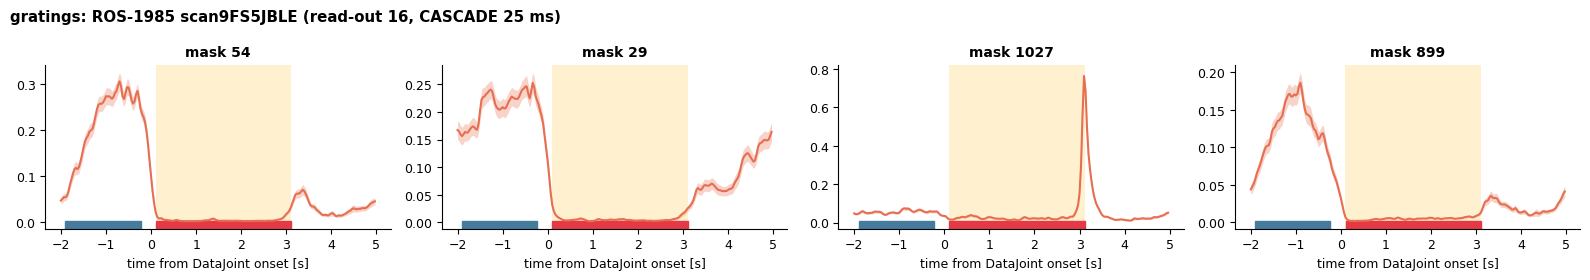

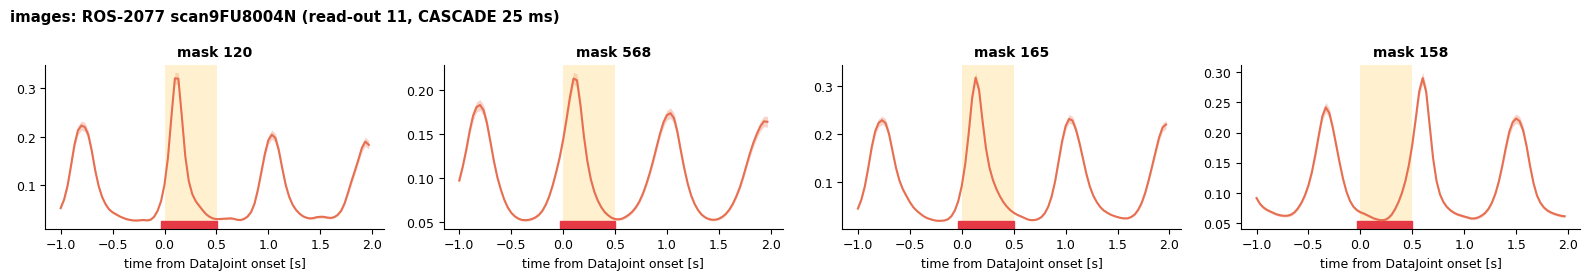

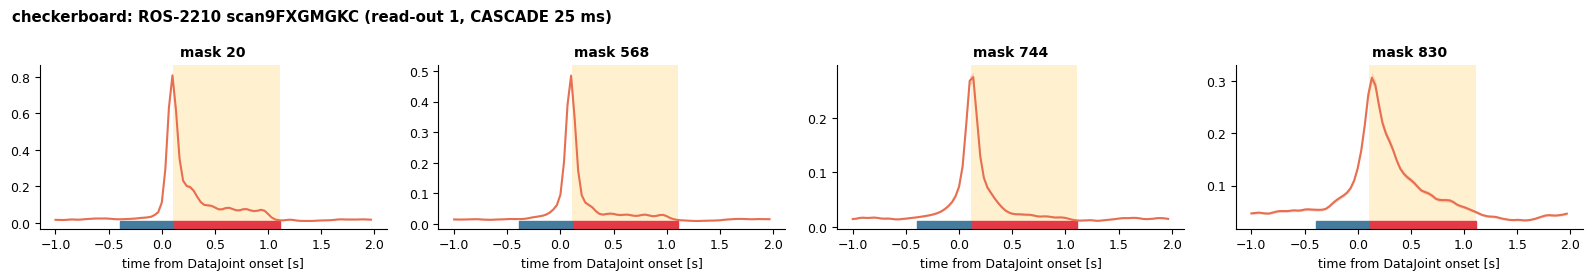

In [10]:
rng = np.random.default_rng(1)
def frame_times(k):
    return (event.Event & {"session_id": k["session_id"], "scan_id": k["scan_id"]} & 'event_type LIKE "%%2p_frames%%"').fetch(
        "event_start_time", order_by="event_start_time").astype(float)
for sel in ("gratings", "nat_images_repeated", "rf_checkerboard"):
    ro = STD_RO[(sel, "cascade25")]
    ks = (r.Readout & {"event_selector": sel, "trace_source": "cascade25", "readout_idx": ro}).fetch("KEY")
    if not ks: print(sel, "not computed yet"); continue
    k = ks[rng.integers(len(ks))]
    zk = {**k, "zeta_idx": 1}
    best = ((r.Zeta.Cell * SOMA - REJ) & zk).fetch("mask", order_by="zeta_p", limit=4)
    row = (r.Readout & k).fetch1()
    on = (r.EventSet.Onset * event.Event & k).fetch("event_start_time", order_by="onset_idx").astype(float)
    ft = frame_times(k); pre, post = (2.0, 5.0) if sel == "gratings" else (1.0, 2.0)
    g = np.arange(-pre, post, 1 / 30)
    fig, ax = plt.subplots(1, 4, figsize=(16, 2.8))
    for a_, m_ in zip(ax, best):
        x = np.asarray((imaging.Activity.Trace & {kk: k[kk] for kk in ("session_id", "scan_id", "paramset_idx", "curation_id")}
                        & {"extraction_method": "cascade_inference_25ms_filter", "mask": int(m_)}).fetch1("activity_trace"), float)
        n = min(len(x), len(ft)); M = np.vstack([np.interp(t + g, ft[:n], x[:n], left=np.nan, right=np.nan) for t in on])
        mu, se = np.nanmean(M, 0), np.nanstd(M, 0) / np.sqrt(len(on))
        a_.fill_between(g, mu - se, mu + se, color=COL["cascade25"], alpha=.3, lw=0); a_.plot(g, mu, color=COL["cascade25"])
        a_.axvspan(row["latency_s"], row["latency_s"] + float(np.nanmedian((event.Event & (r.EventSet.Onset & k)).fetch("event_end_time").astype(float) - on)), color="#ffd166", alpha=.3, lw=0)
        a_.axvspan(row["resp_start_s"], row["resp_stop_s"], ymax=.05, color="#e63946")
        if row["base_start_s"] is not None and np.isfinite(row["base_start_s"]): a_.axvspan(row["base_start_s"], row["base_stop_s"], ymax=.05, color="#457b9d")
        a_.set(title=f"mask {int(m_)}", xlabel="time from DataJoint onset [s]")
    fig.suptitle(f"{PAR[sel]}: {subj.get(k['session_id'])} {k['scan_id']} (read-out {ro}, CASCADE 25 ms)", x=.01, ha="left", fontweight="bold")
    plt.tight_layout(); plt.show()

## Verdict

In [11]:
V = pd.DataFrame(VERDICT)
display(V.style.apply(lambda s: ["background-color: #d8f3dc" if v == "pass" else "background-color: #ffd6a5" for v in s], subset=["result"]))
print(f"{(V.result == 'pass').sum()} of {len(V)} checks pass")

,check,expected,found,result
0,all staged work computed,100 % per table,11921 / 11921 rows,pass
1,no job errors,0,0,pass
2,no empty onset sets,0,0,pass
3,photodiode latency plausible,median 70–130 ms,90 ms,pass
4,no negative detector gain,0,0,pass
5,RoiQC covers every staged curation,561,561,pass
6,"false positives on random onsets (CASCADE, OASIS)",≤ 8 % for every test,max 7.1 %,pass
7,"gratings responsive (CASCADE, read-out 16)",median 50–95 % (pilot 79 %),72 %,pass
8,gratings activated among all soma (CASCADE),majority > 50 %,60 %,pass
9,"images responsive (OASIS, ZETA on read-out 3)",median 40–95 % (pilot 79 %),75 %,pass


24 of 24 checks pass
